# Mini-Project 5: Taxi Route Revenue, Pricing & Fleet Planner

Three 14-seater matatu routes out of Kampala (Ntinda, Entebbe, Mukono). This notebook covers
(1) a `Route` class, (2) supply-demand equilibrium, (3) forecasting with walk-forward backtesting,
(4) fleet planning, and (5) the seasonal-naïve extension.

*Note: only the Ntinda figures come from the original question; the other routes' data are illustrative.*

## Setup: the `Route` class

In [1]:
from abc import ABC, abstractmethod
import math
import statistics

import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import solve


class Route:
    def __init__(self, name, passenger_counts, fare_ugx):
        self.name = str(name)
        self.passenger_counts = np.asarray(passenger_counts, dtype=float)
        self.fare_ugx = float(fare_ugx)

        if self.passenger_counts.ndim != 1 or len(self.passenger_counts) == 0:
            raise ValueError("Passenger counts must be a non-empty 1-D array.")
        if not np.all(np.isfinite(self.passenger_counts)):
            raise ValueError("Passenger counts must be finite.")
        if np.any(self.passenger_counts < 0):
            raise ValueError("Passenger counts cannot be negative.")
        if self.fare_ugx < 0:
            raise ValueError("Fare cannot be negative.")

    def daily_revenue(self):
        return self.passenger_counts * self.fare_ugx

    def total_revenue(self):
        return float(self.daily_revenue().sum())

    def descriptive_stats(self):
        counts = self.passenger_counts.tolist()
        return {
            "mean": statistics.mean(counts),
            "median": statistics.median(counts),
            "variance": statistics.variance(counts),
            "std_dev": statistics.stdev(counts),
        }


## Forecasters
Abstract `Forecaster` base class with four subclasses: 3-day moving average, simple exponential smoothing (tunable α), linear trend, and seasonal-naïve (used in the extension).

In [2]:
class Forecaster(ABC):
    def __init__(self):
        self.days = None
        self.values = None

    def fit(self, days, values):
        self.days = np.asarray(days, dtype=float)
        self.values = np.asarray(values, dtype=float)

        if self.days.ndim != 1 or self.values.ndim != 1:
            raise ValueError("Days and values must be one-dimensional.")
        if len(self.days) != len(self.values) or len(self.values) == 0:
            raise ValueError("Days and values must have equal, non-zero lengths.")
        if not np.all(np.isfinite(self.values)):
            raise ValueError("Values must be finite.")

        self._fit_model()
        return self

    @abstractmethod
    def _fit_model(self):
        pass

    @abstractmethod
    def predict(self, horizon):
        pass


class MovingAverageForecaster(Forecaster):
    def __init__(self, window=3):
        super().__init__()
        self.window = window

    def _fit_model(self):
        if len(self.values) < self.window:
            raise ValueError("Not enough observations for this window.")
        self.level = float(np.mean(self.values[-self.window:]))

    def predict(self, horizon):
        if horizon < 1:
            raise ValueError("horizon must be positive.")
        return np.full(horizon, self.level)


class SimpleExponentialSmoothing(Forecaster):
    def __init__(self, alpha=0.3):
        super().__init__()
        if not 0 < alpha <= 1:
            raise ValueError("alpha must be in (0, 1].")
        self.alpha = float(alpha)

    def _fit_model(self):
        level = self.values[0]
        for value in self.values[1:]:
            level = self.alpha * value + (1 - self.alpha) * level
        self.level = float(level)

    def predict(self, horizon):
        if horizon < 1:
            raise ValueError("horizon must be positive.")
        return np.full(horizon, self.level)


class LinearTrendForecaster(Forecaster):
    def _fit_model(self):
        self.coefficients = np.polyfit(self.days, self.values, deg=1)

    def predict(self, horizon):
        if horizon < 1:
            raise ValueError("horizon must be positive.")
        future_days = np.arange(
            self.days[-1] + 1,
            self.days[-1] + horizon + 1,
        )
        return np.polyval(self.coefficients, future_days)


class SeasonalNaiveForecaster(Forecaster):
    def __init__(self, season_length=7):
        super().__init__()
        self.season_length = season_length

    def _fit_model(self):
        if len(self.values) < self.season_length:
            raise ValueError("Need at least one full season of data.")

    def predict(self, horizon):
        if horizon < 1:
            raise ValueError("horizon must be positive.")

        history = list(self.values)
        predictions = []

        for _ in range(horizon):
            next_prediction = history[-self.season_length]
            predictions.append(next_prediction)
            history.append(next_prediction)

        return np.asarray(predictions, dtype=float)


## Task 1: Route data and descriptive statistics

In [3]:
routes = [
    Route("Kampala-Ntinda",  [35, 40, 42, 50, 55, 60, 48, 52, 47, 45], 2_000),
    Route("Kampala-Entebbe", [60, 58, 65, 70, 72, 80, 75, 68, 66, 64], 5_000),
    Route("Kampala-Mukono",  [45, 47, 50, 49, 55, 62, 58, 53, 51, 50], 3_000),
]

print("Route statistics (passenger counts)")
for route in routes:
    stats = route.descriptive_stats()
    print(
        f"{route.name}: mean={stats['mean']:.2f}, median={stats['median']:.2f}, "
        f"sample variance={stats['variance']:.2f}, sample SD={stats['std_dev']:.2f}, "
        f"10-day revenue=UGX {route.total_revenue():,.0f}"
    )

Route statistics (passenger counts)
Kampala-Ntinda: mean=47.40, median=47.50, sample variance=54.27, sample SD=7.37, 10-day revenue=UGX 948,000
Kampala-Entebbe: mean=67.80, median=67.00, sample variance=45.07, sample SD=6.71, 10-day revenue=UGX 3,390,000
Kampala-Mukono: mean=52.00, median=50.50, sample variance=26.44, sample SD=5.14, 10-day revenue=UGX 1,560,000


**Interpretation.** Entebbe carries the most passengers (mean 67.8) and, with the highest fare, earns by far the most revenue. Ntinda has the highest variability (SD 7.37) relative to its mean, so its demand is the hardest to plan for. Mukono is the steadiest (SD 5.14).

## Task 2: Supply-demand equilibrium (Ntinda)

In [4]:
# Demand: Q = 120 - 0.02P  ->   0.02P + Q = 120
# Supply: Q = 10 + 0.03P   ->  -0.03P + Q = 10
A = np.array([[0.02, 1.0],
              [-0.03, 1.0]])
b = np.array([120.0, 10.0])

P_eq, Q_eq = solve(A, b)

current_fare = 2_000
demand_at_current = 120 - 0.02 * current_fare
supply_at_current = 10 + 0.03 * current_fare
position = "below" if current_fare < P_eq else "above"

print(f"Equilibrium fare: UGX {P_eq:,.0f}")
print(f"Equilibrium quantity: {Q_eq:.0f} passengers per trip-hour")
print(f"At UGX {current_fare:,}: demand={demand_at_current:.0f}, supply={supply_at_current:.0f}")
print(f"The current fare is {position} equilibrium "
      f"(gap = UGX {abs(P_eq - current_fare):,.0f}); "
      f"{'shortage' if demand_at_current > supply_at_current else 'surplus'} = "
      f"{abs(demand_at_current - supply_at_current):.0f} passengers per trip-hour")

Equilibrium fare: UGX 2,200
Equilibrium quantity: 76 passengers per trip-hour
At UGX 2,000: demand=80, supply=70
The current fare is below equilibrium (gap = UGX 200); shortage = 10 passengers per trip-hour


**Interpretation.** The equilibrium fare is **UGX 2,200** at **76 passengers per trip-hour**. The current fare of UGX 2,000 is **below** equilibrium: at that price 80 passengers want a seat but operators would only supply 70, a **shortage of 10 passengers per trip-hour** (queues, unmet demand). Raising the fare toward UGX 2,200 would reduce demand to 76, raise supply to 76 and clear the market. Note these Q values are per trip-hour, so they are not directly comparable to the daily passenger counts above.

## Task 3: Walk-forward backtest, α tuning and day-11 forecasts

For each test day *t* = 4…10, every model is fitted only on days 1…*t*−1 and predicts day *t*. MAE is reported in passengers and in revenue (UGX). α is tuned by grid search over 0.05…1.00 (SES allows α = 1, which is a naïve "repeat yesterday" forecast).

In [5]:
def rolling_predictions(model_factory, values, first_test_index=3):
    values = np.asarray(values, dtype=float)
    predictions, actuals = [], []
    for test_index in range(first_test_index, len(values)):
        train_values = values[:test_index]
        train_days = np.arange(1, test_index + 1)
        model = model_factory().fit(train_days, train_values)
        predictions.append(max(0.0, float(model.predict(1)[0])))
        actuals.append(values[test_index])
    return np.asarray(actuals), np.asarray(predictions)


alpha_grid = np.round(np.arange(0.05, 1.0001, 0.05), 2)
backtest = {}

for route in routes:
    y = route.passenger_counts
    actual, ma_pred = rolling_predictions(lambda: MovingAverageForecaster(window=3), y)
    _, lt_pred = rolling_predictions(lambda: LinearTrendForecaster(), y)

    alpha_scores, alpha_preds = {}, {}
    for alpha in alpha_grid:
        _, p = rolling_predictions(lambda a=alpha: SimpleExponentialSmoothing(alpha=a), y)
        alpha_scores[float(alpha)] = float(np.mean(np.abs(actual - p)))
        alpha_preds[float(alpha)] = p
    best_alpha = min(alpha_scores, key=alpha_scores.get)

    ses_name = f"SES (alpha={best_alpha:.2f})"
    preds = {"3-day moving average": ma_pred, ses_name: alpha_preds[best_alpha], "linear trend": lt_pred}
    maes = {k: float(np.mean(np.abs(actual - v))) for k, v in preds.items()}
    best_model_name = min(maes, key=maes.get)

    all_days = np.arange(1, len(y) + 1)
    if best_model_name == "3-day moving average":
        best_model = MovingAverageForecaster(window=3)
    elif best_model_name.startswith("SES"):
        best_model = SimpleExponentialSmoothing(alpha=best_alpha)
    else:
        best_model = LinearTrendForecaster()
    day11_pass = max(0.0, float(best_model.fit(all_days, y).predict(1)[0]))

    backtest[route.name] = {
        "actual": actual, "preds": preds, "mae": maes, "best_alpha": best_alpha,
        "alpha_scores": alpha_scores, "selected_model": best_model_name,
        "day11_passengers": day11_pass, "day11_revenue": day11_pass * route.fare_ugx,
    }

    print(f"\n{route.name}  (best alpha = {best_alpha:.2f})")
    print(f"  {'Model':<24}{'MAE (pax)':>10}{'MAE (UGX)':>14}")
    for k, v in maes.items():
        print(f"  {k:<24}{v:>10.3f}{v * route.fare_ugx:>14,.0f}")
    print(f"  Selected: {best_model_name}")

print("\nSES alpha grid (MAE, passengers)")
print("alpha  " + "  ".join(f"{r.name.split('-')[1]:>8}" for r in routes))
for a in alpha_grid:
    print(f"{a:5.2f}  " + "  ".join(f"{backtest[r.name]['alpha_scores'][float(a)]:8.3f}" for r in routes))


Kampala-Ntinda  (best alpha = 1.00)
  Model                    MAE (pax)     MAE (UGX)
  3-day moving average         7.524        15,048
  SES (alpha=1.00)             5.857        11,714
  linear trend                 7.873        15,747
  Selected: SES (alpha=1.00)

Kampala-Entebbe  (best alpha = 1.00)
  Model                    MAE (pax)     MAE (UGX)
  3-day moving average         7.190        35,952
  SES (alpha=1.00)             4.429        22,143
  linear trend                 7.711        38,557
  Selected: SES (alpha=1.00)

Kampala-Mukono  (best alpha = 1.00)
  Model                    MAE (pax)     MAE (UGX)
  3-day moving average         5.333        16,000
  SES (alpha=1.00)             3.714        11,143
  linear trend                 6.391        19,172
  Selected: SES (alpha=1.00)

SES alpha grid (MAE, passengers)
alpha    Ntinda   Entebbe    Mukono
 0.05    13.030     8.825     7.358
 0.10    10.604     7.679     5.999
 0.15     8.881     7.217     5.363
 0.20     7

### Actual vs forecast revenue
Solid line = actual revenue; dashed = walk-forward forecasts for days 4-10 (selected model); star = day-11 forecast.

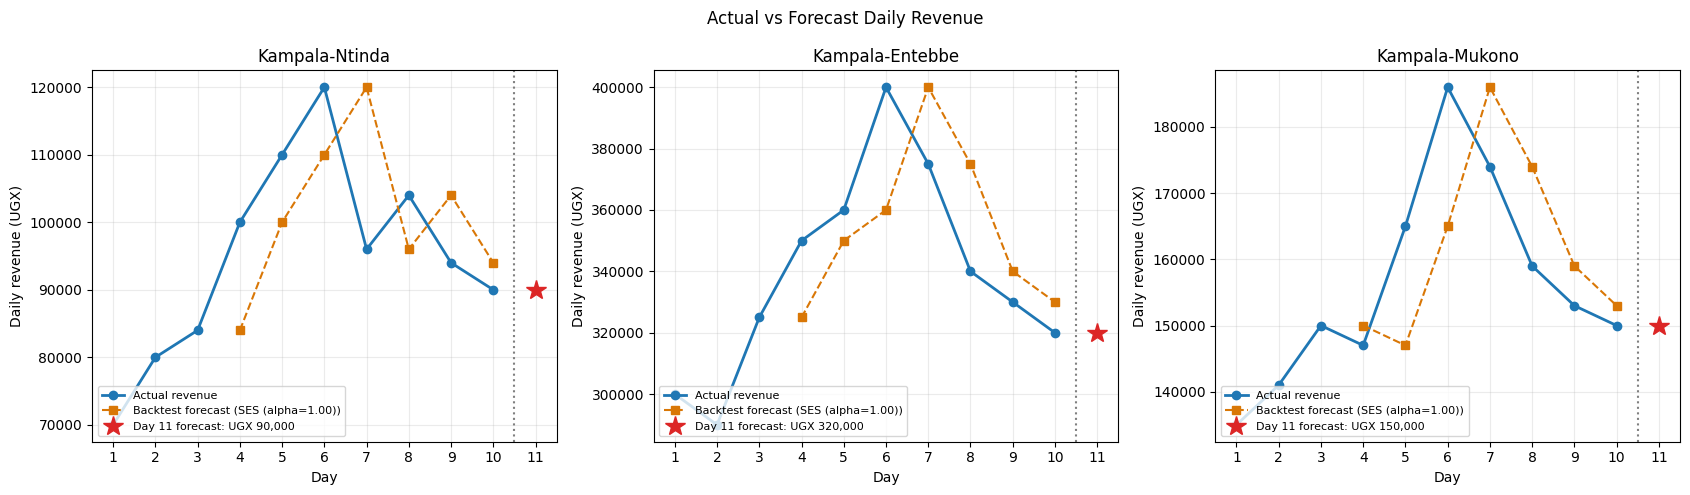

Day-11 forecasts
Kampala-Ntinda: model=SES (alpha=1.00), passengers=45.00, revenue=UGX 90,000
Kampala-Entebbe: model=SES (alpha=1.00), passengers=64.00, revenue=UGX 320,000
Kampala-Mukono: model=SES (alpha=1.00), passengers=50.00, revenue=UGX 150,000


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, route in zip(axes, routes):
    res = backtest[route.name]
    fare = route.fare_ugx
    days = np.arange(1, 11)
    ax.plot(days, route.daily_revenue(), marker="o", linewidth=2, label="Actual revenue")
    ax.plot(np.arange(4, 11), res["preds"][res["selected_model"]] * fare,
            marker="s", linestyle="--", color="#d97706",
            label=f"Backtest forecast ({res['selected_model']})")
    ax.plot([11], [res["day11_revenue"]], marker="*", markersize=15, color="#dc2626",
            linestyle="None", label=f"Day 11 forecast: UGX {res['day11_revenue']:,.0f}")
    ax.axvline(10.5, color="gray", linestyle=":")
    ax.set_title(route.name)
    ax.set_xlabel("Day")
    ax.set_ylabel("Daily revenue (UGX)")
    ax.set_xticks(range(1, 12))
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, loc="lower left")

fig.suptitle("Actual vs Forecast Daily Revenue")
fig.tight_layout()
plt.show()

print("Day-11 forecasts")
for route in routes:
    r = backtest[route.name]
    print(f"{route.name}: model={r['selected_model']}, passengers={r['day11_passengers']:.2f}, "
          f"revenue=UGX {r['day11_revenue']:,.0f}")

**Interpretation.** SES beats both the 3-day moving average and the linear trend on every route, but the grid search picks **α = 1.00** (the top of the grid) on every route, so SES degenerates into a pure "repeat yesterday" forecast; MAE falls steadily as α rises, meaning smoothing never helped on this data. The 10-day series are short and noisy (a spike on day 6, then decline), so smoothing over several days lags behind and a straight trend line fits poorly. With only 7 test days, and with α tuned and the model selected on the same window, these MAEs are slightly optimistic and the ranking should be treated as indicative rather than conclusive.

## Task 4: Fleet planning for day 11
Each vehicle makes 8 one-way trips/day x 14 passengers = **112 passenger-seats per day**. Required vehicles = ceil(forecast passengers x 1.15 / 112).

In [7]:
CAPACITY_PER_VEHICLE = 8 * 14   # 112 passengers per vehicle per day
BUFFER = 1.15

print(f"{'Route':<18}{'Forecast pax':>13}{'With 15% buffer':>17}{'Vehicles (raw)':>16}{'Vehicles':>10}{'Utilisation':>13}")
for route in routes:
    r = backtest[route.name]
    needed = r["day11_passengers"] * BUFFER
    raw = needed / CAPACITY_PER_VEHICLE
    vehicles = math.ceil(raw)
    r["vehicles"] = vehicles
    util = r["day11_passengers"] / (vehicles * CAPACITY_PER_VEHICLE)
    print(f"{route.name:<18}{r['day11_passengers']:>13.1f}{needed:>17.1f}{raw:>16.2f}{vehicles:>10}{util:>12.0%}")

Route              Forecast pax  With 15% buffer  Vehicles (raw)  Vehicles  Utilisation
Kampala-Ntinda             45.0             51.7            0.46         1         40%
Kampala-Entebbe            64.0             73.6            0.66         1         57%
Kampala-Mukono             50.0             57.5            0.51         1         45%


**Interpretation.** Each route needs just **1 vehicle** on day 11 (raw requirement 0.46-0.66 vehicles; rounded **up** so demand is always covered). Since one vehicle can carry 112 passengers a day, utilisation is only about 40-57%, so the 15% buffer never changes the answer. The association could consider sharing one vehicle across routes or reassigning spare capacity, if trip timing allows.

## Extension: 60-day weekly pattern and seasonal-naïve

Simulated demand = route mean x weekday multiplier + Gaussian noise (6% of the mean). Day 1 is Monday; Friday is busiest (x1.28) and Sunday quietest (x0.72). We compare a 7-day seasonal-naïve forecaster (value from one week earlier) to the 3-day moving average, using the same walk-forward backtest from day 8 onwards.

Single simulation (seed 2026)
Kampala-Ntinda: seasonal-naive MAE=2.83; 3-day-MA MAE=7.71; seasonal naive wins=True
Kampala-Entebbe: seasonal-naive MAE=4.30; 3-day-MA MAE=9.33; seasonal naive wins=True
Kampala-Mukono: seasonal-naive MAE=4.70; 3-day-MA MAE=8.06; seasonal naive wins=True

Robustness over 200 random simulations
Kampala-Ntinda: seasonal-naive wins 200/200; mean MAE seasonal=3.14 vs 3-day MA=7.12


Kampala-Entebbe: seasonal-naive wins 200/200; mean MAE seasonal=4.50 vs 3-day MA=10.18
Kampala-Mukono: seasonal-naive wins 200/200; mean MAE seasonal=3.45 vs 3-day MA=7.81


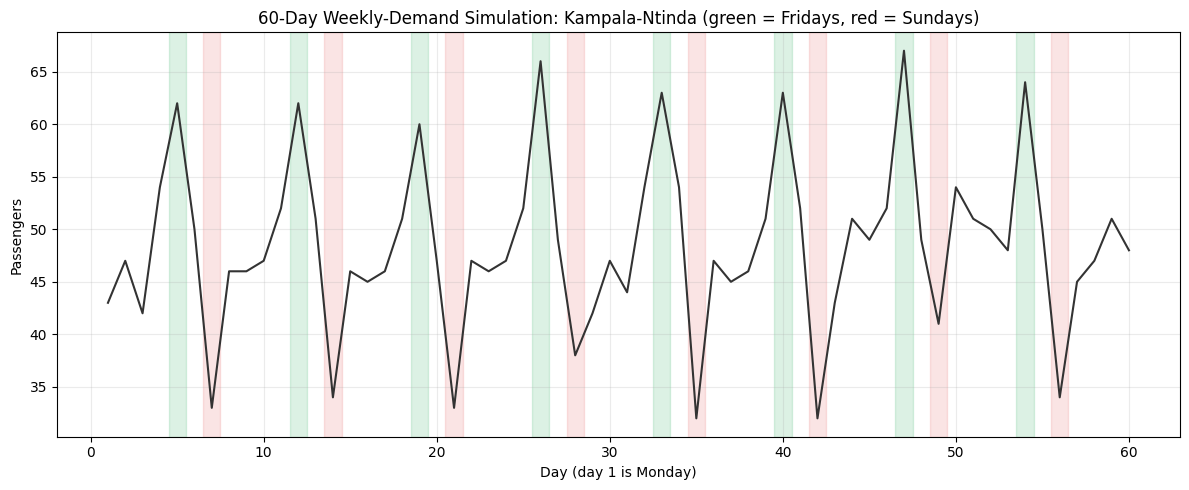

In [8]:
weekday_multipliers = np.array([0.96, 0.98, 1.00, 1.05, 1.28, 1.08, 0.72])  # Mon..Sun

def simulate(route, rng, n_days=60):
    base = route.passenger_counts.mean()
    wd = np.arange(n_days) % 7
    noisy = base * weekday_multipliers[wd] + rng.normal(0, 0.06 * base, size=n_days)
    return np.maximum(0, np.rint(noisy))

def compare(series):
    a, p_s = rolling_predictions(lambda: SeasonalNaiveForecaster(7), series, first_test_index=7)
    _, p_m = rolling_predictions(lambda: MovingAverageForecaster(3), series, first_test_index=7)
    return np.mean(np.abs(a - p_s)), np.mean(np.abs(a - p_m))

rng = np.random.default_rng(2026)
extension_results = {}
print("Single simulation (seed 2026)")
for route in routes:
    series = simulate(route, rng)
    s_mae, m_mae = compare(series)
    extension_results[route.name] = series
    print(f"{route.name}: seasonal-naive MAE={s_mae:.2f}; 3-day-MA MAE={m_mae:.2f}; "
          f"seasonal naive wins={s_mae < m_mae}")

# Robustness: repeat over many random seeds
n_seeds = 200
print(f"\nRobustness over {n_seeds} random simulations")
for route in routes:
    wins, s_all, m_all = 0, [], []
    for seed in range(n_seeds):
        s_mae, m_mae = compare(simulate(route, np.random.default_rng(seed)))
        wins += s_mae < m_mae
        s_all.append(s_mae); m_all.append(m_mae)
    print(f"{route.name}: seasonal-naive wins {wins}/{n_seeds}; "
          f"mean MAE seasonal={np.mean(s_all):.2f} vs 3-day MA={np.mean(m_all):.2f}")

# Plot with day-of-week shading for the Ntinda example
name = routes[0].name
series = extension_results[name]
plt.figure(figsize=(12, 5))
plt.plot(np.arange(1, 61), series, color="#333333", label="Simulated passengers")
for d in range(1, 61):
    if (d - 1) % 7 == 4:
        plt.axvspan(d - 0.5, d + 0.5, color="#16a34a", alpha=0.15)
    if (d - 1) % 7 == 6:
        plt.axvspan(d - 0.5, d + 0.5, color="#dc2626", alpha=0.12)
plt.title(f"60-Day Weekly-Demand Simulation: {name} (green = Fridays, red = Sundays)")
plt.xlabel("Day (day 1 is Monday)")
plt.ylabel("Passengers")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretation.** The seasonal-naïve forecaster has roughly half the error of the 3-day moving average on every route, and it wins in essentially every one of the repeated simulations, not just the seed we happened to use. A 3-day average smooths across the weekly cycle, so it under-predicts Fridays and over-predicts Sundays; seasonal-naïve copies the same weekday from last week, so it captures the pattern directly.